In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

%matplotlib inline

In [2]:
# Read the dataset (CSV file must be in the same folder as this notebook)
df = pd.read_csv('emails - emails.csv')

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (5172, 3002)


,Email No.,the,to,ect,and,for,of,a,you,hou,...,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
0,Email 1,0,0,1,0,0,0,2,0,0,...,0,0,0,0,0,0,0,0,0,0
1,Email 2,8,13,24,6,6,2,102,1,27,...,0,0,0,0,0,0,0,1,0,0
2,Email 3,0,0,1,0,0,0,8,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Email 4,0,5,22,0,5,1,51,2,10,...,0,0,0,0,0,0,0,0,0,0
4,Email 5,7,6,17,1,5,2,57,0,9,...,0,0,0,0,0,0,0,1,0,0


In [3]:
# Display column names
print(df.columns)

# Check missing values
print(df.isnull().sum().sum())

# Remove rows containing missing values
df.dropna(inplace=True)

# Remove the email ID column because it is not a predictive feature
if 'Email No.' in df.columns:
    df.drop('Email No.', axis=1, inplace=True)

# Separate input features (X) and target (y)
X = df.drop('Prediction', axis=1)
y = df['Prediction']

print("Features shape:", X.shape)
print("Target distribution:")
print(y.value_counts())

Index(['Email No.', 'the', 'to', 'ect', 'and', 'for', 'of', 'a', 'you', 'hou',
       ...
       'connevey', 'jay', 'valued', 'lay', 'infrastructure', 'military',
       'allowing', 'ff', 'dry', 'Prediction'],
      dtype='str', length=3002)
0
Features shape: (5172, 3000)
Target distribution:
Prediction
0    3672
1    1500
Name: count, dtype: int64


In [4]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# Scale features using training data only
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (3620, 3000)
Testing data: (1552, 3000)


In [5]:
# Create KNN classifier with 7 neighbors
knn = KNeighborsClassifier(n_neighbors=7)

# Train the model
knn.fit(X_train, y_train)

# Predict the test data
knn_pred = knn.predict(X_test)

print("KNN Predictions:")
print(knn_pred)

KNN Predictions:
[0 1 0 ... 0 0 1]


In [6]:
# Calculate KNN accuracy and confusion matrix
knn_accuracy = accuracy_score(y_test, knn_pred)
print("KNN Accuracy:", knn_accuracy)

knn_cm = confusion_matrix(y_test, knn_pred)
print("KNN Confusion Matrix:\n", knn_cm)

print("KNN Classification Report:")
print(classification_report(y_test, knn_pred))

KNN Accuracy: 0.7905927835051546
KNN Confusion Matrix:
 [[800 302]
 [ 23 427]]
KNN Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.73      0.83      1102
           1       0.59      0.95      0.72       450

    accuracy                           0.79      1552
   macro avg       0.78      0.84      0.78      1552
weighted avg       0.86      0.79      0.80      1552



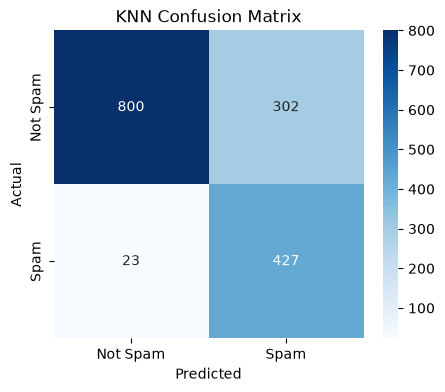

In [7]:
# Visualize KNN confusion matrix
plt.figure(figsize=(5, 4))
sns.heatmap(knn_cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Not Spam', 'Spam'],
            yticklabels=['Not Spam', 'Spam'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('KNN Confusion Matrix')
plt.show()

In [8]:
# Create SVM classifier with C = 1
svm = SVC(C=1)

# Train the model
svm.fit(X_train, y_train)

# Predict the test data
svm_pred = svm.predict(X_test)

print("SVM Predictions:")
print(svm_pred)

SVM Predictions:
[0 0 0 ... 0 0 1]


In [9]:
# Calculate SVM accuracy and confusion matrix
svm_accuracy = accuracy_score(y_test, svm_pred)
print("SVM Accuracy:", svm_accuracy)

svm_cm = confusion_matrix(y_test, svm_pred)
print("SVM Confusion Matrix:\n", svm_cm)

print("SVM Classification Report:")
print(classification_report(y_test, svm_pred))

SVM Accuracy: 0.9207474226804123
SVM Confusion Matrix:
 [[1096    6]
 [ 117  333]]
SVM Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.99      0.95      1102
           1       0.98      0.74      0.84       450

    accuracy                           0.92      1552
   macro avg       0.94      0.87      0.90      1552
weighted avg       0.93      0.92      0.92      1552



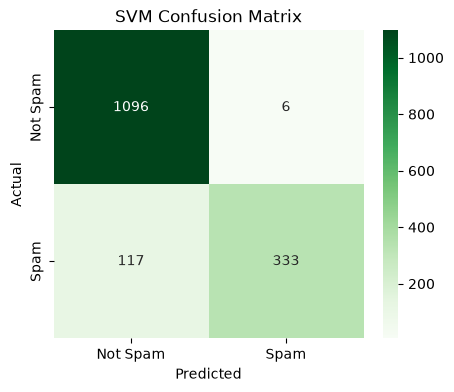

In [10]:
# Visualize SVM confusion matrix
plt.figure(figsize=(5, 4))
sns.heatmap(svm_cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Not Spam', 'Spam'],
            yticklabels=['Not Spam', 'Spam'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('SVM Confusion Matrix')
plt.show()

  Classifier  Accuracy
0        KNN  0.790593
1        SVM  0.920747


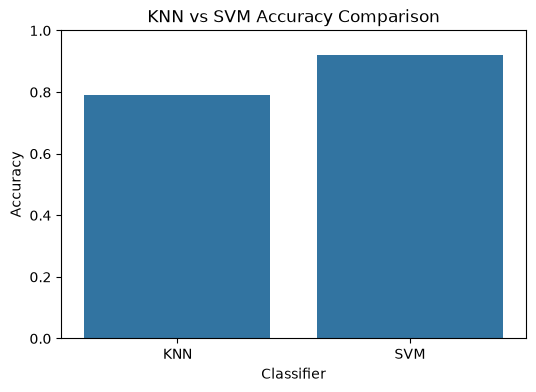

SVM gives better accuracy for this train-test split.


In [12]:
# Compare the accuracy of both classifiers
comparison = pd.DataFrame({
    'Classifier': ['KNN', 'SVM'],
    'Accuracy': [knn_accuracy, svm_accuracy]
})

print(comparison)

plt.figure(figsize=(6, 4))
sns.barplot(data=comparison, x='Classifier', y='Accuracy')
plt.ylim(0, 1)
plt.title('KNN vs SVM Accuracy Comparison')
plt.ylabel('Accuracy')
plt.show()

if knn_accuracy > svm_accuracy:
    print("KNN gives better accuracy for this train-test split.")
elif svm_accuracy > knn_accuracy:
    print("SVM gives better accuracy for this train-test split.")
else:
    print("Both classifiers give the same accuracy.")